# Praktikum Data Mining: Evaluasi Model Klasifikasi

**Nama:** M Yusqo Hidayatulhaq  
**NIM:** 24343058  
**Prodi:** Informatika, Fakultas Teknik, Universitas Negeri Padang

Notebook ini berisi langkah praktikum 4.1 sampai 4.8 serta jawaban Tugas 1
pada modul Evaluasi Model Klasifikasi: confusion matrix, accuracy, precision,
recall, dan F1-score untuk deteksi fraud transaksi pembayaran digital.


In [1]:
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option("display.width", 100)

RANDOM_STATE = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

## 4.1 Dataset sintetis transaksi pembayaran digital

Dataset dibangkitkan deterministik dengan `default_rng(42)` agar hasil dapat
direproduksi. Label `isFraud` diturunkan dari kombinasi fitur melalui fungsi
sigmoid, sehingga kelas fraud menjadi langka (data tidak seimbang).

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n = 500

amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

score = (
    -4.5
    + 0.45 * (amount > 300)
    + 1.1 * new_device
    + 1.5 * foreign_ip
    + 0.7 * (hour < 5)
)
prob = 1 / (1 + np.exp(-score))
isFraud = rng.binomial(1, prob)

df = pd.DataFrame(
    {
        "amount": amount.round(2),
        "hour": hour,
        "new_device": new_device,
        "foreign_ip": foreign_ip,
        "isFraud": isFraud,
    }
)

df.head()

,amount,hour,new_device,foreign_ip,isFraud
0,201.28,9,0,0,0
1,52.46,8,0,0,0
2,314.33,17,1,0,0
3,380.15,3,0,0,0
4,21.09,5,1,0,0


In [3]:
print("Distribusi kelas:")
print(df["isFraud"].value_counts().sort_index().to_string())

prop = df["isFraud"].mean()
print(f"\nTotal transaksi : {len(df)}")
print(f"Fraud           : {int(df['isFraud'].sum())} ({prop * 100:.2f}%)")
print(f"Normal          : {len(df) - int(df['isFraud'].sum())} ({(1 - prop) * 100:.2f}%)")

Distribusi kelas:
isFraud
0    484
1     16

Total transaksi : 500
Fraud           : 16 (3.20%)
Normal          : 484 (96.80%)


## 4.2 Split data dan latih Decision Tree

Data dibagi 70:30 dengan stratifikasi agar proporsi kelas tetap. Model
dibatasi `max_depth=4` dan memakai `class_weight='balanced'` karena kelas
fraud hanya 3,2% dari data.

In [4]:
X = df.drop(columns="isFraud")
y = df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

model = DecisionTreeClassifier(
    max_depth=4, class_weight="balanced", random_state=RANDOM_STATE
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Data latih : {len(y_train)}")
print(f"Data uji   : {len(y_test)}")
print(f"Fraud di data uji: {int(y_test.sum())} ({y_test.mean() * 100:.2f}%)")
print(f"Kedalaman pohon: {model.get_depth()}, jumlah leaf: {model.get_n_leaves()}")

Data latih : 350
Data uji   : 150
Fraud di data uji: 5 (3.33%)
Kedalaman pohon: 4, jumlah leaf: 12


## 4.3 Confusion matrix

`labels=[0, 1]` membuat susunan matriks `[[TN, FP], [FN, TP]]`, dan
`cm.ravel()` mengembalikan urutan TN, FP, FN, TP.

In [5]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix:")
print(cm)
print(f"\nTP={tp}, TN={tn}, FP={fp}, FN={fn}")

Confusion matrix:
[[113  32]
 [  3   2]]

TP=2, TN=113, FP=32, FN=3


## 4.4 Perhitungan manual dan verifikasi scikit-learn

Metrik dihitung manual dari TP/TN/FP/FN, lalu dibandingkan dengan
`accuracy_score`, `precision_score`, `recall_score`, dan `f1_score`.

In [6]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0.0
recall = tp / (tp + fn) if tp + fn else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

print("Manual :")
print(f"  Accuracy  = ({tp}+{tn})/{tp + tn + fp + fn} = {accuracy:.4f}")
print(f"  Precision = {tp}/({tp}+{fp}) = {precision:.4f}")
print(f"  Recall    = {tp}/({tp}+{fn}) = {recall:.4f}")
print(f"  F1-score  = {f1:.4f}")

skor = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
}
print("\nscikit-learn :")
for nama, nilai in skor.items():
    print(f"  {nama:<10} = {nilai:.4f}")
print("\nSelisih manual vs sklearn:")
print(
    f"  accuracy={abs(accuracy - skor['accuracy']):.2e}, "
    f"precision={abs(precision - skor['precision']):.2e}, "
    f"recall={abs(recall - skor['recall']):.2e}, "
    f"f1={abs(f1 - skor['f1']):.2e}"
)

Manual :
  Accuracy  = (2+113)/150 = 0.7667
  Precision = 2/(2+32) = 0.0588
  Recall    = 2/(2+3) = 0.4000
  F1-score  = 0.1026

scikit-learn :
  accuracy   = 0.7667
  precision  = 0.0588
  recall     = 0.4000
  f1         = 0.1026

Selisih manual vs sklearn:
  accuracy=0.00e+00, precision=0.00e+00, recall=0.00e+00, f1=0.00e+00


## 4.5 Visualisasi confusion matrix

Gambar disimpan ke `figures/confusion_matrix.png` untuk dilampirkan pada
laporan.

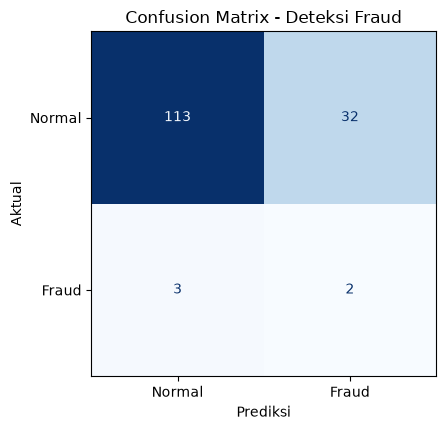

In [7]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"]).plot(
    cmap="Blues", values_format="d", ax=ax, colorbar=False
)
ax.set_title("Confusion Matrix - Deteksi Fraud")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=160)
plt.show()

## 4.7 Baseline semua transaksi diprediksi normal

Baseline ini menunjukkan bahwa accuracy tinggi belum tentu berarti model
mampu mendeteksi fraud.

In [8]:
baseline = np.zeros(len(y_test), dtype=int)
print(f"Baseline accuracy: {accuracy_score(y_test, baseline):.4f}")
print(f"Baseline recall fraud: {recall_score(y_test, baseline, zero_division=0):.4f}")

print("\nclassification_report baseline (labels=[0,1]):")
print(classification_report(y_test, baseline, labels=[0, 1], zero_division=0))

print("classification_report Decision Tree (labels=[0,1]):")
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

Baseline accuracy: 0.9667
Baseline recall fraud: 0.0000

classification_report baseline (labels=[0,1]):
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

classification_report Decision Tree (labels=[0,1]):
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



## 4.8 Pengaruh ambang prediksi

Ambang 0,2; 0,4; 0,5; dan 0,7 diuji dengan peluang fraud dari
`predict_proba`. Nilai probabilitas unik ditampilkan karena pohon keputusan
hanya menghasilkan peluang diskret per leaf.

In [9]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]

rows = []
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0),
            "tp": int(tp_t),
            "fp": int(fp_t),
            "fn": int(fn_t),
            "tn": int(tn_t),
        }
    )

thr_df = pd.DataFrame(rows)
thr_df

,threshold,precision,recall,f1,tp,fp,fn,tn
0,0.2,0.058824,0.4,0.102564,2,32,3,113
1,0.4,0.058824,0.4,0.102564,2,32,3,113
2,0.5,0.058824,0.4,0.102564,2,32,3,113
3,0.7,0.055556,0.2,0.086957,1,17,4,128


In [10]:
uniq = np.unique(np.round(y_prob, 4))
print(f"Probabilitas unik dari leaf pohon ({len(uniq)}): {uniq.tolist()}")

Probabilitas unik dari leaf pohon (6): [0.0, 0.1826, 0.5424, 0.8486, 0.9391, 1.0]


## Tugas 1 Hitung manual

Diketahui TP = 24, TN = 156, FP = 12, dan FN = 8. Nilai dihitung dengan rumus
pada modul tanpa memakai pustaka.

In [11]:
t1 = {"tp": 24, "tn": 156, "fp": 12, "fn": 8}
total1 = sum(t1.values())

acc1 = (t1["tp"] + t1["tn"]) / total1
prec1 = t1["tp"] / (t1["tp"] + t1["fp"])
rec1 = t1["tp"] / (t1["tp"] + t1["fn"])
f1_1 = 2 * prec1 * rec1 / (prec1 + rec1)

print(f"Confusion matrix: [[TN={t1['tn']}, FP={t1['fp']}], [FN={t1['fn']}, TP={t1['tp']}]]")
print(f"Total observasi : {total1}")
print(f"Accuracy  = ({t1['tp']}+{t1['tn']})/{total1} = {acc1:.4f}")
print(f"Precision = 24/36 = {prec1:.4f}")
print(f"Recall    = 24/32 = {rec1:.4f}")
print(f"F1-score  = {f1_1:.4f}")

Confusion matrix: [[TN=156, FP=12], [FN=8, TP=24]]
Total observasi : 200
Accuracy  = (24+156)/200 = 0.9000
Precision = 24/36 = 0.6667
Recall    = 24/32 = 0.7500
F1-score  = 0.7059


## Catatan hasil

- Confusion matrix data uji: TP = 2, TN = 113, FP = 32, FN = 3.
- Accuracy 0,7667 dengan recall fraud 0,4000 dan precision 0,0588.
- Baseline semua normal mencapai accuracy 0,9667 tetapi recall fraud 0.
- Ambang 0,2 sampai 0,5 memberi hasil identik, ambang 0,7 menaikkan FN.

Pembahasan lengkap ada pada laporan praktikum.